# v005 shaft on three supports: AxisForge FEM against r01 extended, Harris Eq. 9.48 and itself

**Question.** Does the AxisForge shaft FEM solve a hyperstatic shaft (L 270 mm, d 30 mm, supports at 10 / 110 / 260
mm) right with rigid supports, linear radial and rotational springs and settlements, and on three Hertz bearings
(stiff and flexible shaft)?

**Judges.** r01 `solve_supported` (same EI / kGA, point springs, two planes as two calls); Harris2007_vol2 Eqs
9.42-9.44 (PDF p. 285) and Eq. 9.48 (PDF p. 286); for the flexible Hertz shaft: scipy `root`, r01 at the secant
springs, AxisForge with the bearing force fed back as a `RadialLoad`.

**Criteria (README 6).** 1e-9 for every FEM vs r01 / Harris 9.42-9.44 / statics comparison; Newton vs scipy 1e-8 of P;
EI x 1e5 within 1e-4 of P of Eq. 9.48 (H1), the error O(1/EI) (H2): both set after a prototype, so RECORD in this run
(`verdict_next_run` shows what they would say) and criteria from the next. **The fed-back force sign is convention-dependent (R-003).**

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v000_axisforge.v005_shaft_three_supports import study

out = study.run()
fig = {p.stem.split("_", 1)[1]: p for p in out["figures"]}        # v005_<module>_<function>[_<variant>]
print(out["verdicts"])


def table(rows, keys):
    """format_table of the given keys, numbers in 3 significant digits (strings as they are)."""
    text = [{k: f"{r.get(k):.3g}" if isinstance(r.get(k), float) else str(r.get(k)) for k in keys} for r in rows]
    return format_table([(k, k, "s") for k in keys], text)

{'PASS': 129, 'MISS': 3, 'RECORD': 46}


## 1. First check: the sign of a bearing force fed back to the shaft (R-003)
Two pins, 1000 N at 210 deg. Feeding +R_B (as AxisForge reports it, force on the shaft) back as a `RadialLoad`
empties pin B (F0b); -R_B doubles it (F0c). `phi_Fr` of `bearing_nodes` is 180 deg from the load (F0d).

In [2]:
print(table(out["first"] + out["literature"], ["id", "quantity", "value", "judge", "rel_err", "verdict", "tag"]))

 id                                            quantity     value  judge   rel_err  verdict                           tag
---  --------------------------------------------------  --------  -----  --------  -------  ----------------------------
F0a                                R_A + R_B vs -F (XY)       866    866  1.86e-12     PASS  convention-dependent (R-003)
F0a                                R_A + R_B vs -F (XZ)       500    500  1.13e-12     PASS  convention-dependent (R-003)
F0b                R_B after feeding back +R_B (XY, XZ)  2.84e-14      0  1.78e-16     PASS  convention-dependent (R-003)
F0b                R_A after feeding back +R_B (XY, XZ)       727    727         0     PASS  convention-dependent (R-003)
F0c                R_B after feeding back -R_B (XY, XZ)       277    277         0   RECORD  convention-dependent (R-003)
F0d  phi_Fr - direction of the load (from +Z toward +Y)       180    180  1.66e-14   RECORD  convention-dependent (R-003)
 L1                     

## 2. Linear: springs, rotational spring, settlements, both planes (n 27)
Filled markers: AxisForge nodes; lines: r01 (EB) and r01 at kGA_eff (one-point Timoshenko). The shaft passes through
the settled rigid supports (10, 260) and sinks into the middle spring; theta flattens at 260 (rotational spring).

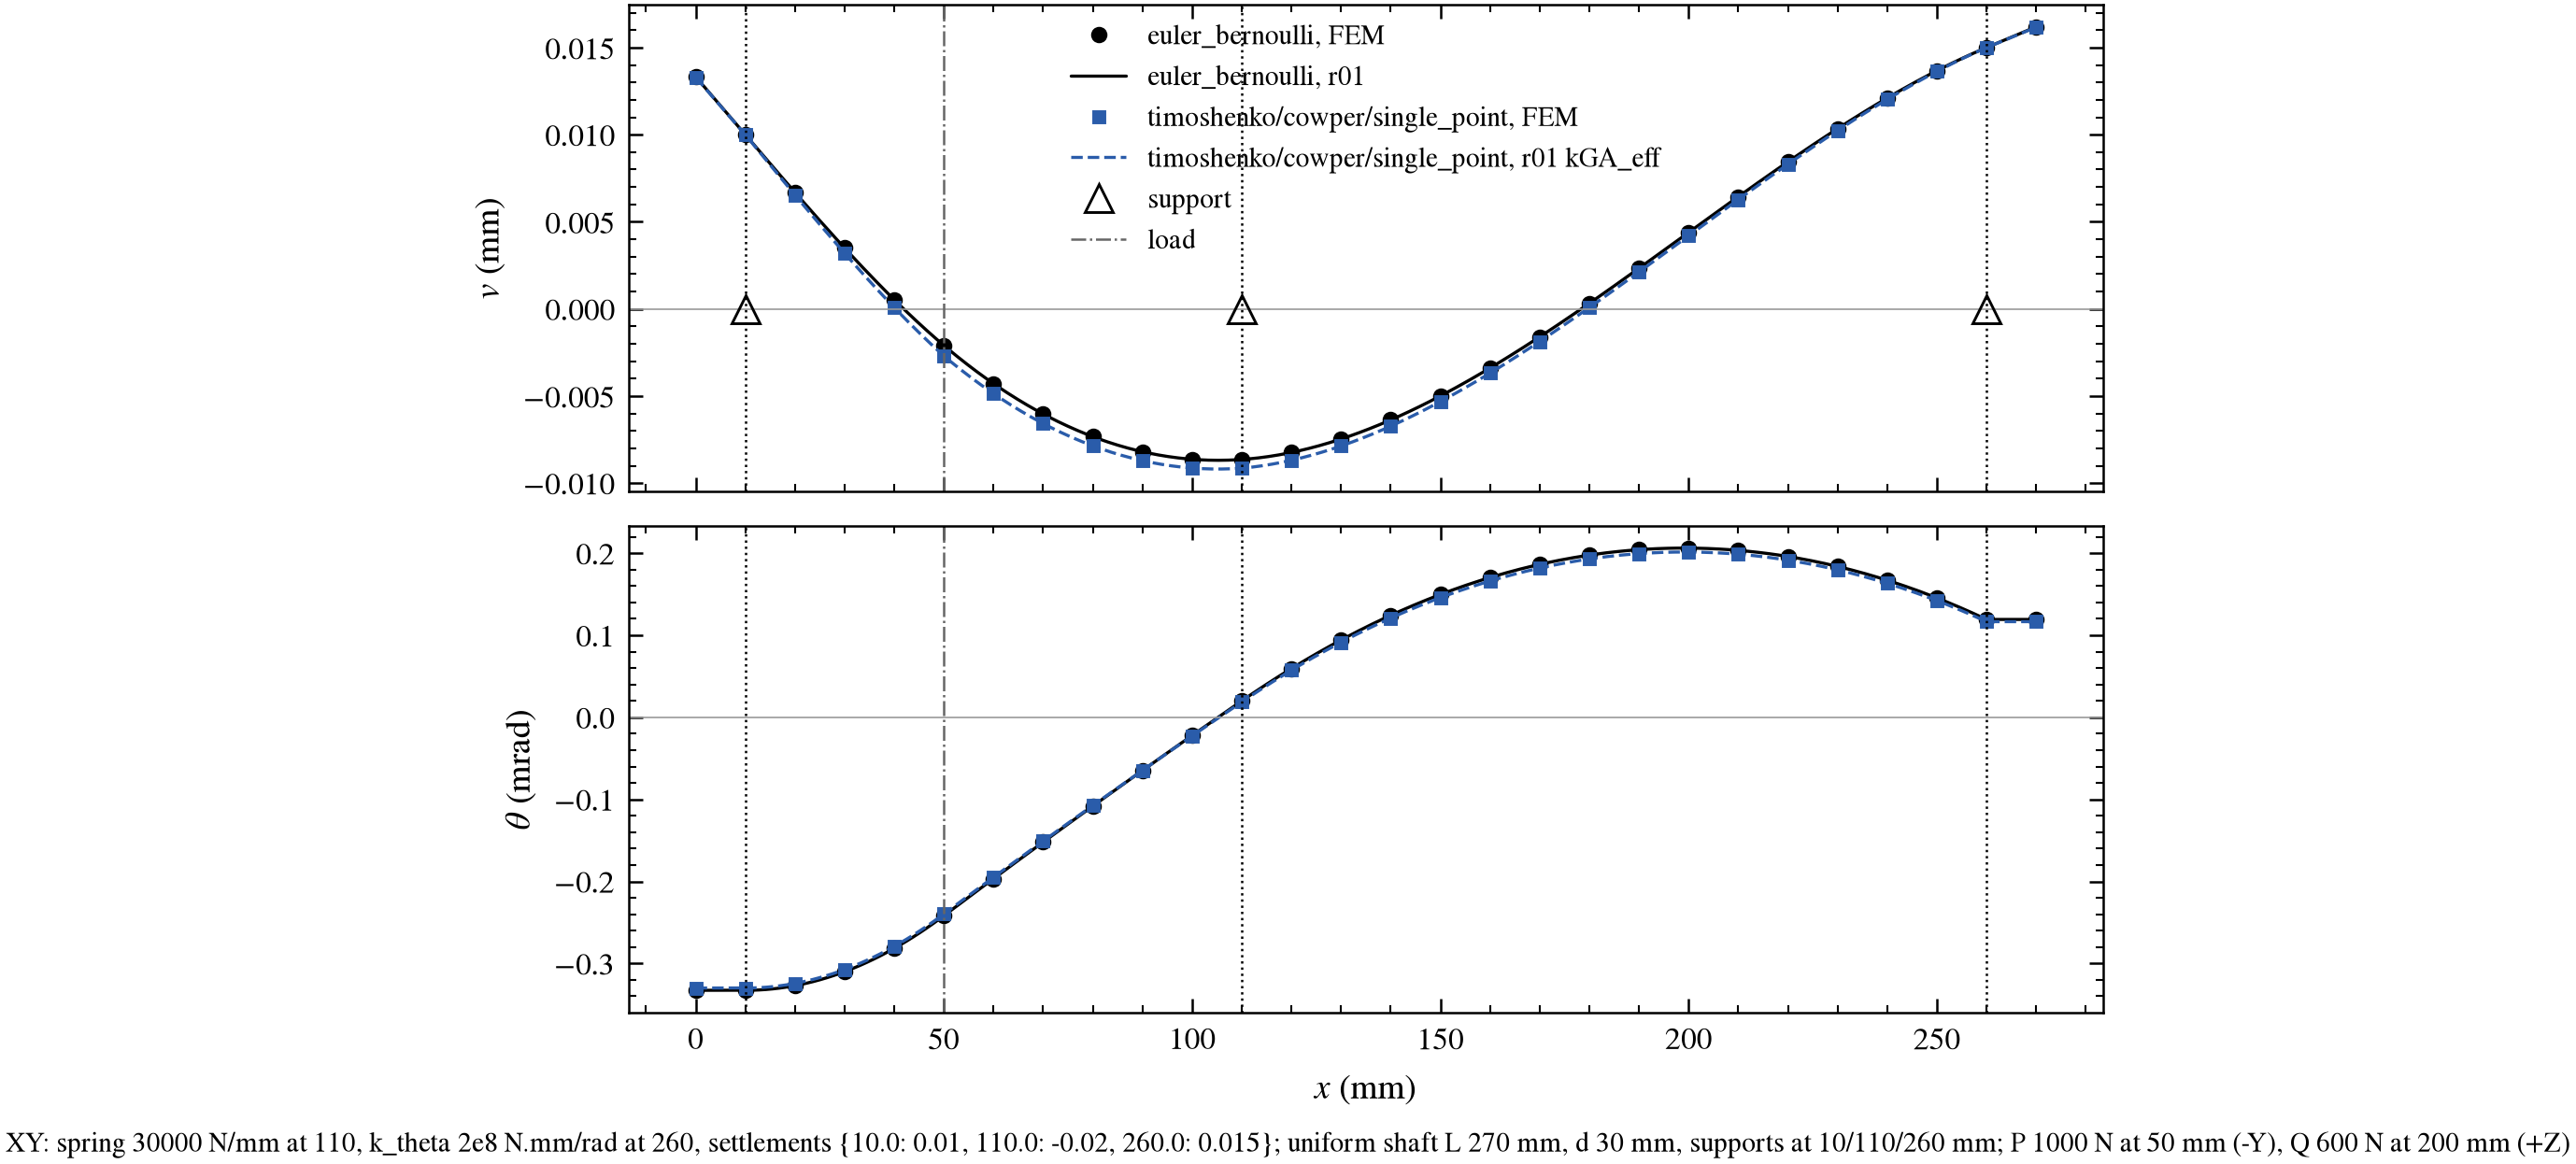

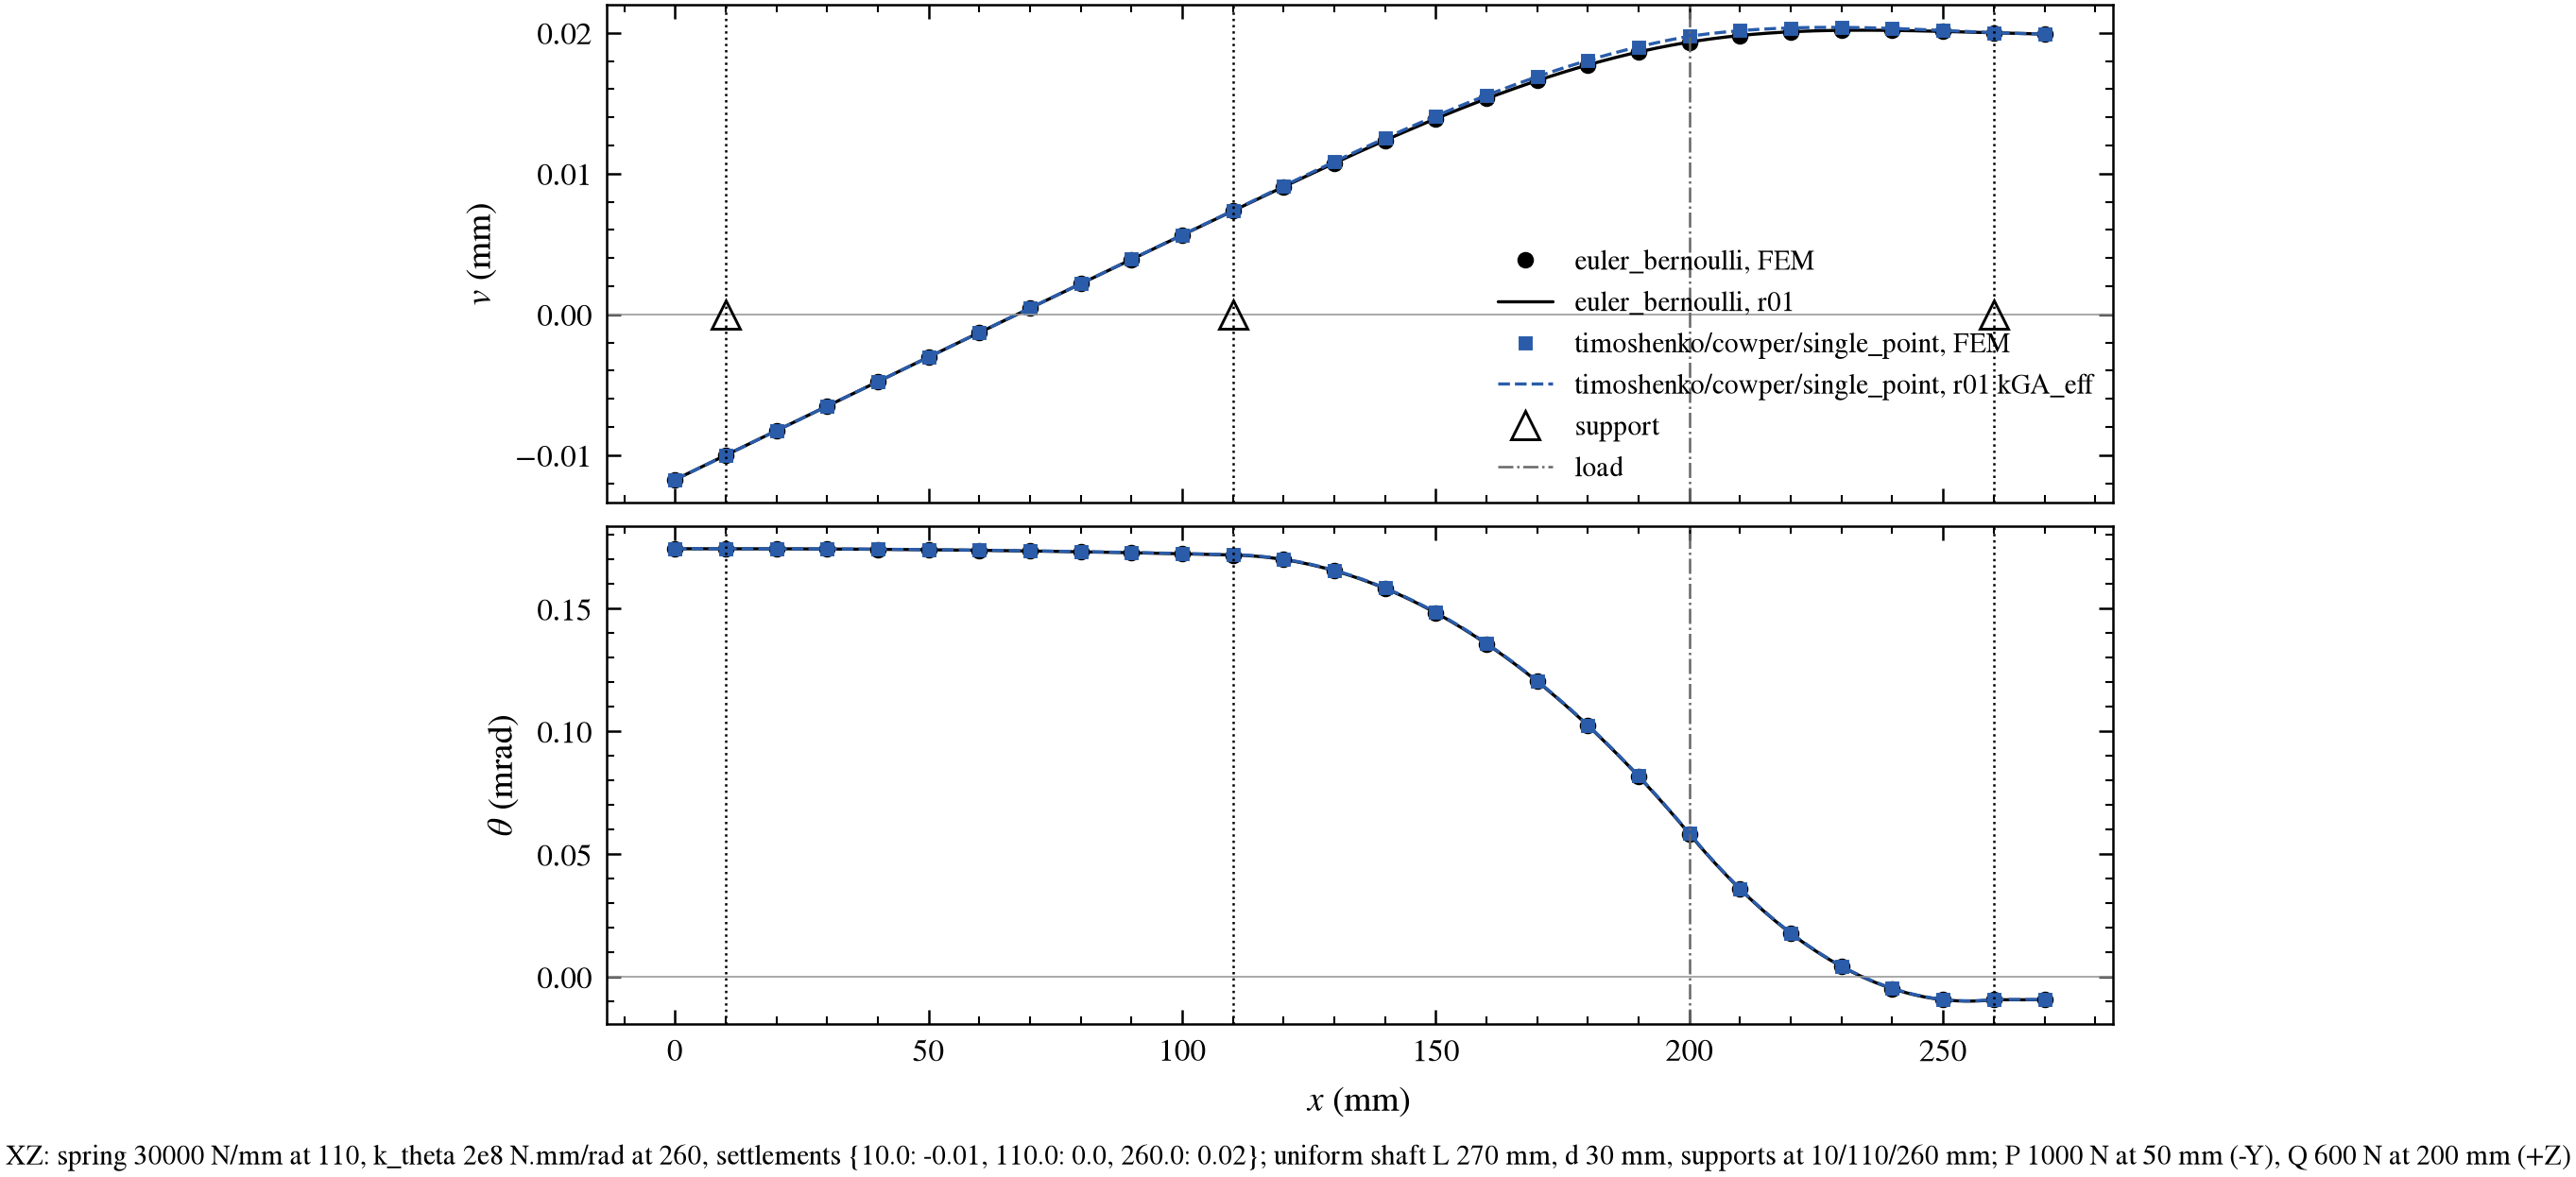

In [3]:
display(Image(filename=str(fig["shaft_deflection_along_shaft_XY_n27"])))
display(Image(filename=str(fig["shaft_deflection_along_shaft_XZ_n27"])))

## 3. Error against the mesh
EB at round-off, growing with cond(K) (R5-33; the spring couple C3c exceeds 1e-9 at n 108 and 216: MISS); one-point
Timoshenko against r01 at kGA_eff at 1e-12, against r01 at kGA as h^2 (dotted guide).

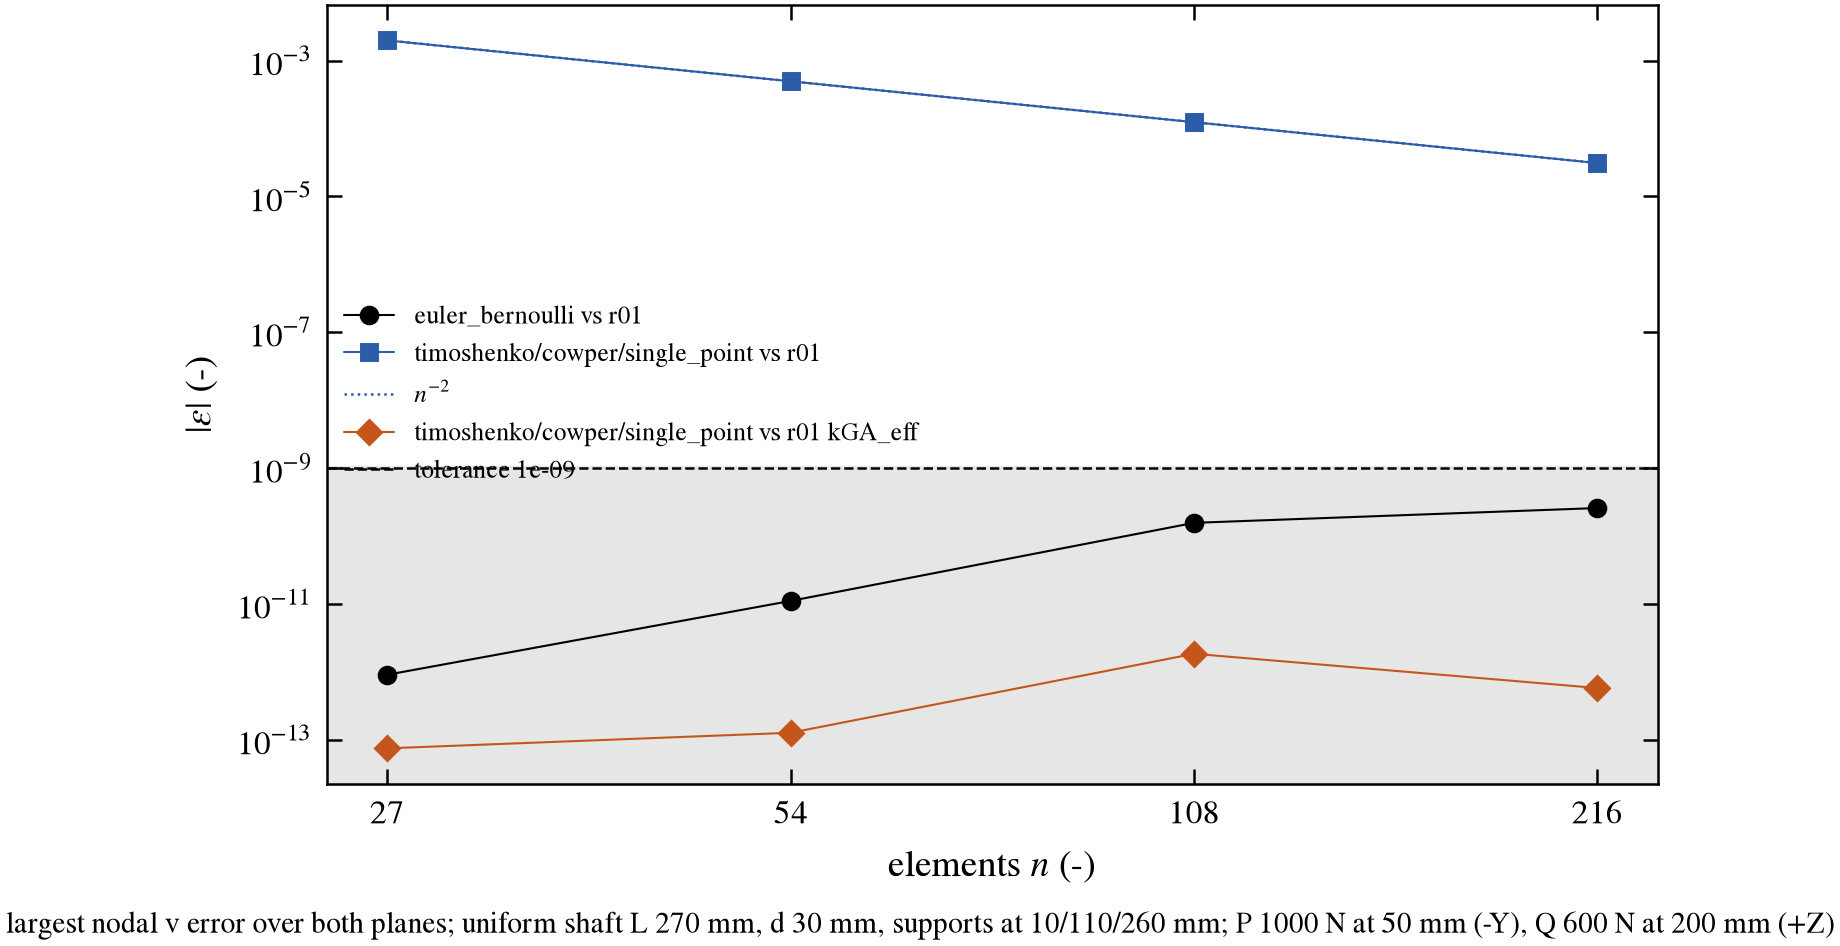

 id                          theory    n  worst rel_err
---  ------------------------------  ---  -------------
 C1                 euler_bernoulli  108       1.56e-10
 C1                 euler_bernoulli  216       2.58e-10
 C1                 euler_bernoulli   27       9.04e-13
 C1                 euler_bernoulli   54        1.1e-11
 C2                 euler_bernoulli  108       2.43e-10
 C2                 euler_bernoulli  216       2.08e-10
 C2                 euler_bernoulli   27       1.27e-12
 C2                 euler_bernoulli   54       1.64e-11
 C3                 euler_bernoulli  108        8.8e-10
 C3                 euler_bernoulli  216       3.32e-10
 C3                 euler_bernoulli   27        5.9e-12
 C3                 euler_bernoulli   54       5.55e-11
 C3  timoshenko/cowper/single_point  108       2.62e-12
 C3  timoshenko/cowper/single_point  216       7.54e-13
 C3  timoshenko/cowper/single_point   27       1.87e-13
 C3  timoshenko/cowper/single_point   54       1

In [4]:
display(Image(filename=str(fig["shaft_error_vs_elements"])))
worst = {}
for r in out["checks"]:
    if r["verdict"] in ("PASS", "MISS"):
        key = (r["id"], r["theory"], r["n_elements"])
        worst[key] = max(worst.get(key, 0.0), abs(r["rel_err"]))
print(table([{"id": k[0], "theory": k[1], "n": k[2], "worst rel_err": v} for k, v in sorted(worst.items(), key=str)],
            ["id", "theory", "n", "worst rel_err"]))

## 4. Reactions against the middle spring: from two supports (k -> 0) to Harris 9.42-9.44 (k -> inf)
R_2 rises from 0 to 0.512 P; R_3 changes sign (0.16 P -> -0.045 P); the lower panel is FEM vs r01 (1e-12).

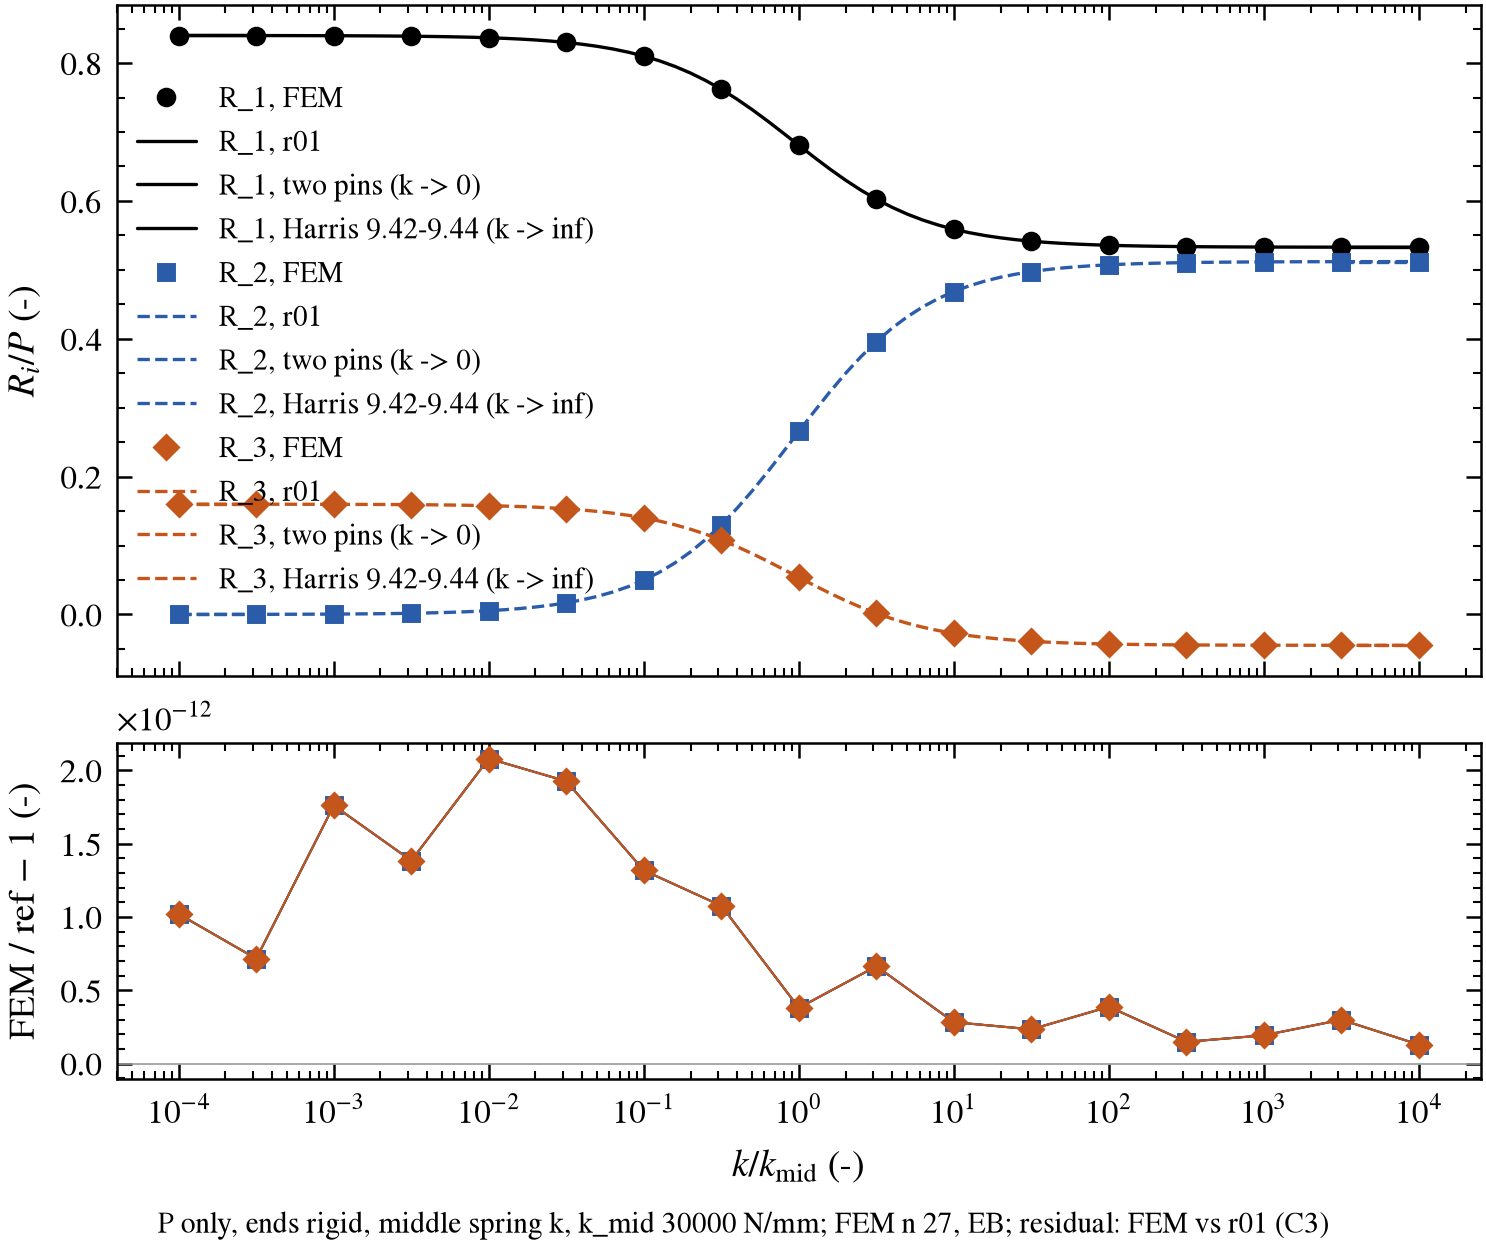

In [5]:
display(Image(filename=str(fig["shaft_ratio_sweep_stiffness"])))

## 5. Flexible shaft on three Hertz bearings: Newton, its residual history and its checks
Newton converges quadratically in 4 iterations; the converged shaft lies on r01 with the secant springs.

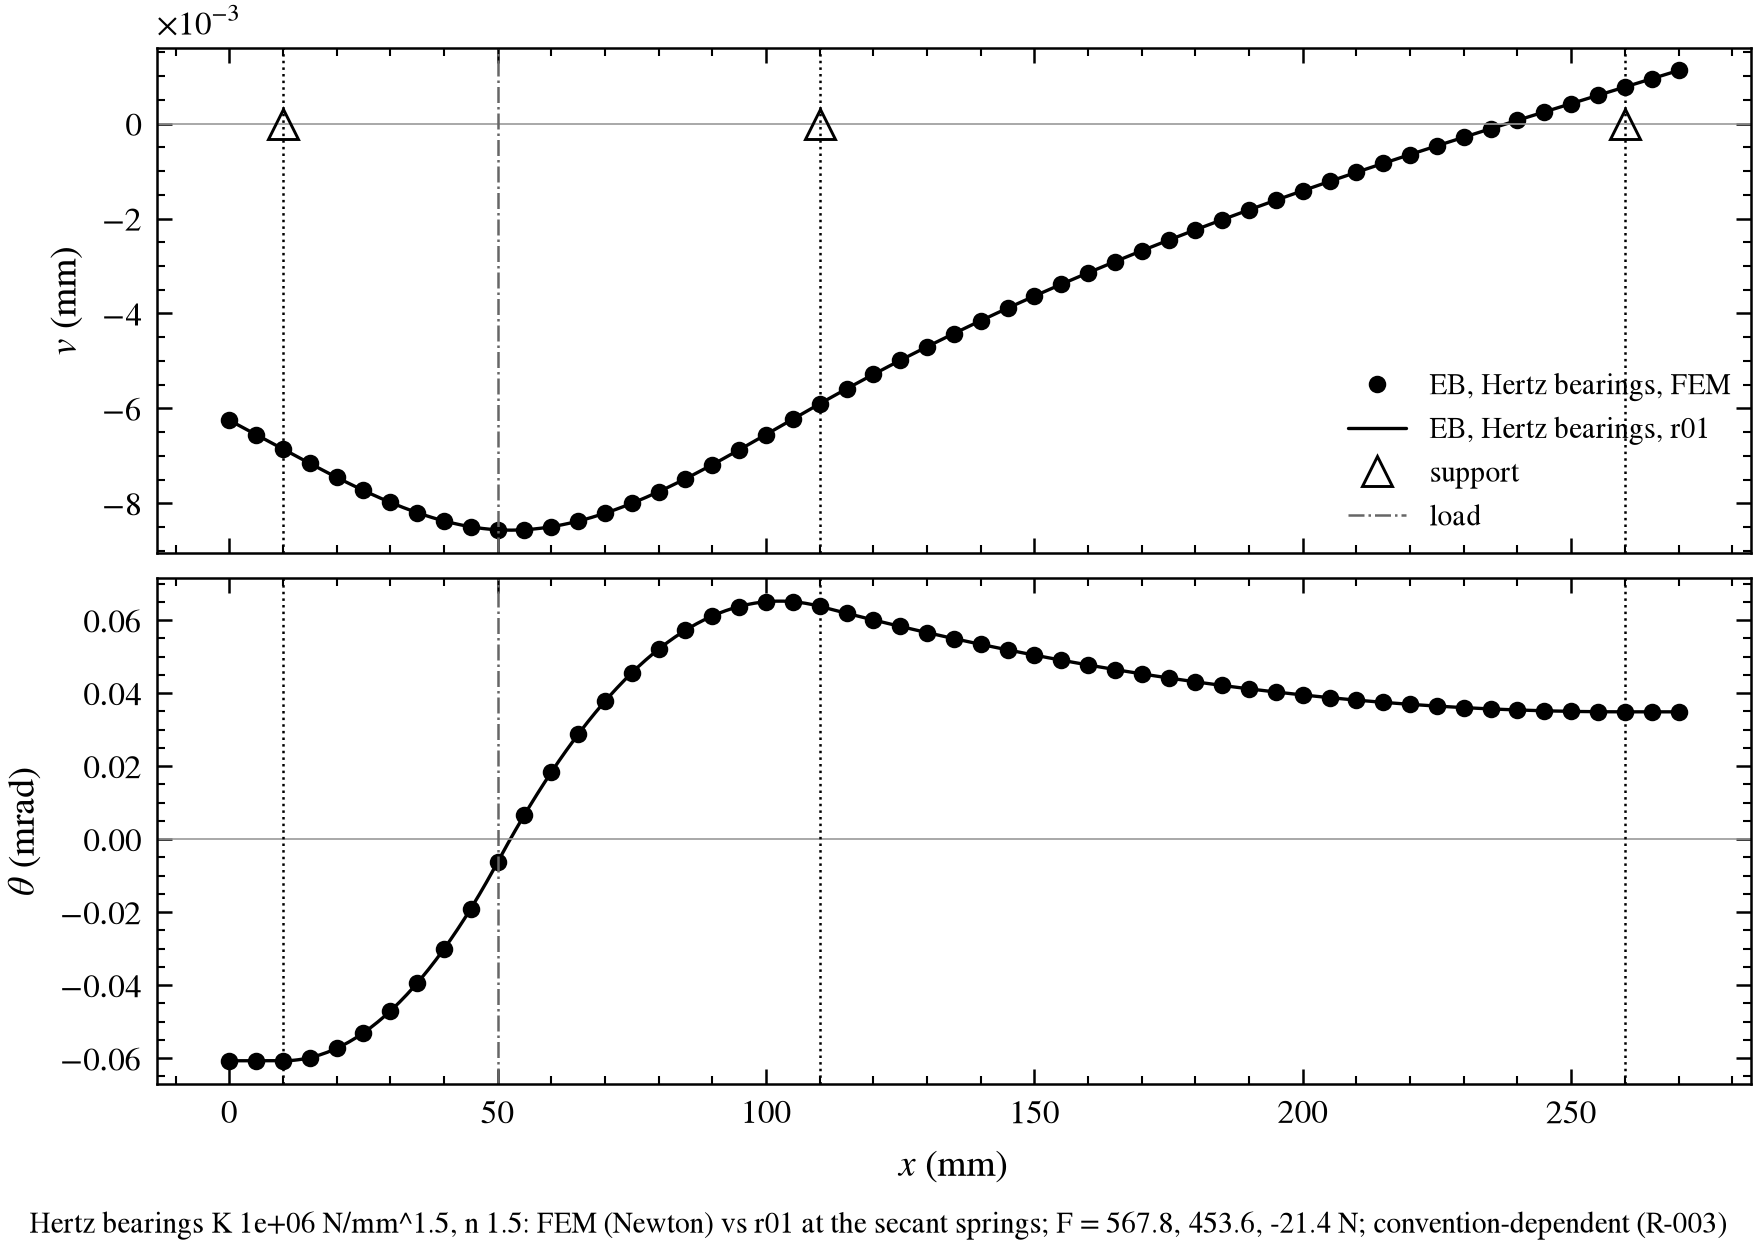

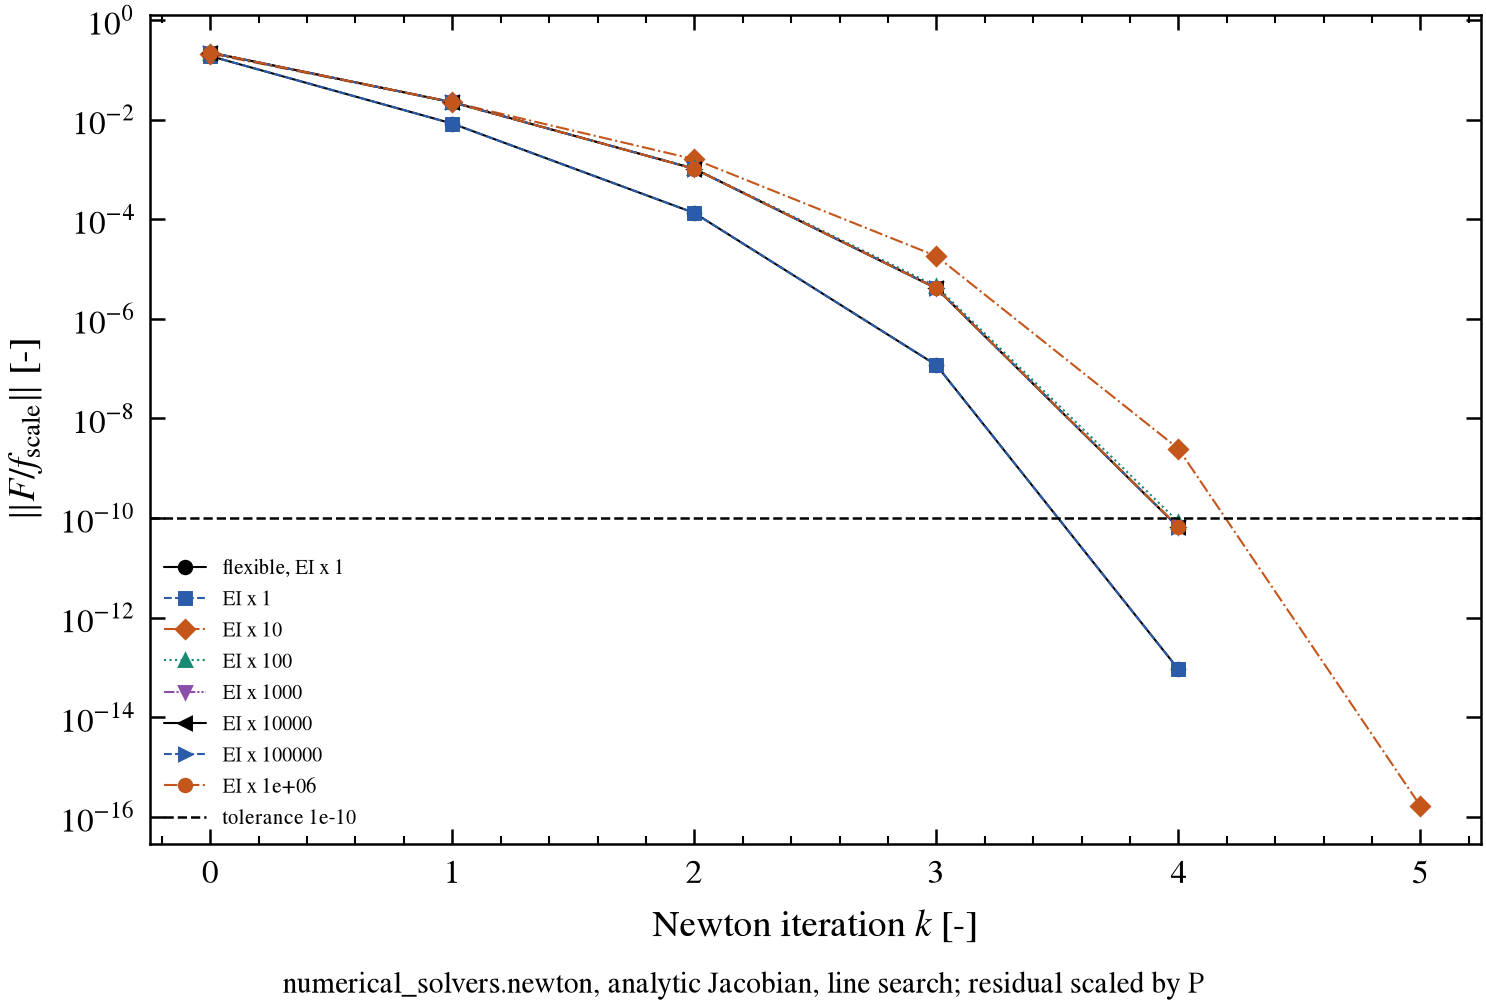

   id                                     quantity   rel_err  verdict                                source
-----  -------------------------------------------  --------  -------  ------------------------------------
   N1                 Newton converged; iterations         0   RECORD                          residual_abs
   N2  bearing forces, Newton vs scipy root (hybr)   8.5e-14     PASS      scipy root success=False nfev=14
N3/C1                                            v  1.59e-11     PASS                                  None
N3/C2                                        theta  1.85e-11     PASS                                  None
N3/C3                                            R  1.81e-11     PASS                                  None
   N4   v at bearing 2, F_2 fed back as RadialLoad  1.02e-11     PASS                 AxisForge, RadialLoad
   N4                   R_1, R_3 with F_2 fed back  4.44e-12     PASS                 AxisForge, RadialLoad
   N5                       

In [6]:
display(Image(filename=str(fig["shaft_deflection_along_shaft_hertz"])))
display(Image(filename=str(fig["convergence_newton_history"])))
print(table(out["hertz"], ["id", "quantity", "rel_err", "verdict", "source"]))

## 6. Stiff shaft: EI x s against Harris Eq. 9.48 (rigid shaft)
The bearing forces reach Harris's lines as s grows; the error falls parallel to the 1/s guide through the H1 tolerance
(marker at s = 1e5) down to a round-off floor near s = 1e6.

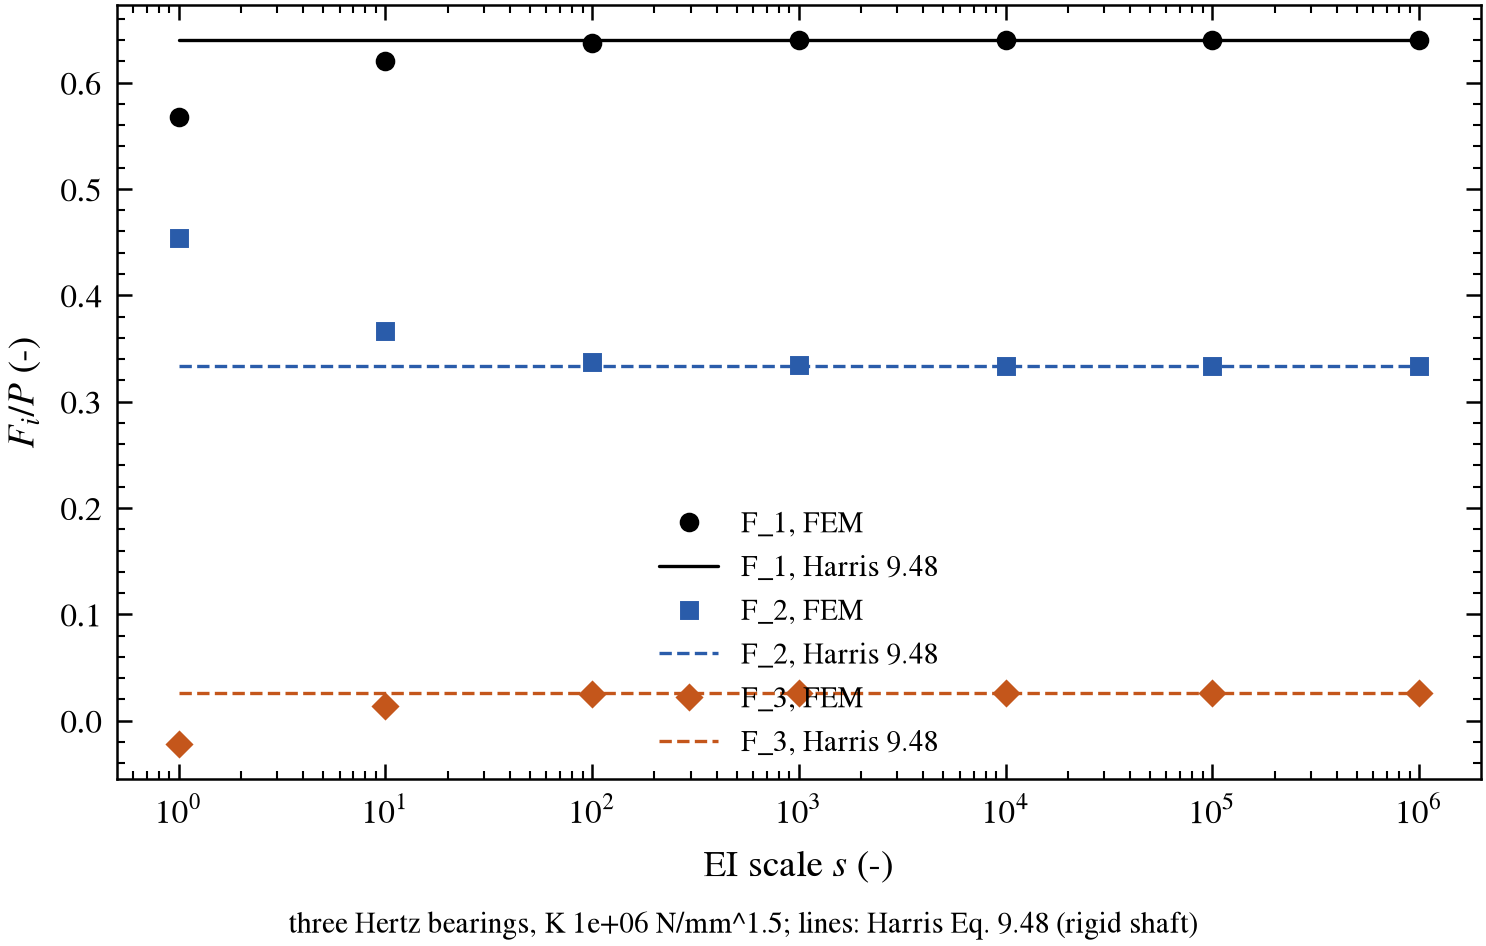

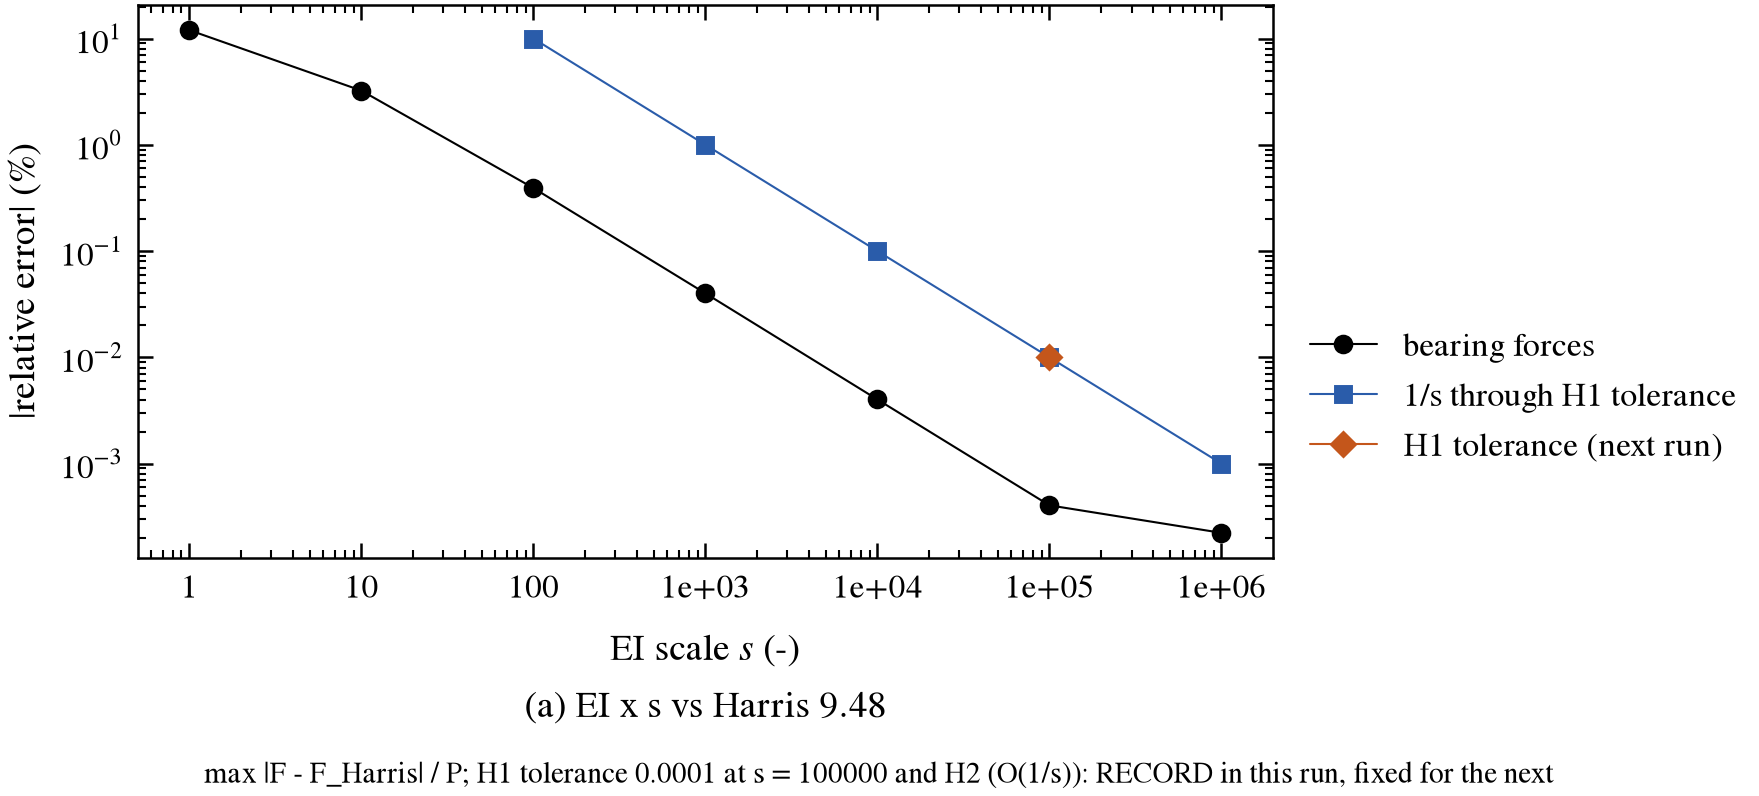

id  ei_scale   rel_err     tol  verdict  verdict_next_run  newton_iter  newton_reason
--  --------  --------  ------  -------  ----------------  -----------  -------------
H0         1      0.12     nan   RECORD              None            4   residual_abs
H0        10    0.0323     nan   RECORD              None            5   residual_abs
H0       100   0.00392     nan   RECORD              None            4   residual_abs
H0     1e+03    0.0004     nan   RECORD              None            4   residual_abs
H0     1e+04  4.01e-05     nan   RECORD              None            4   residual_abs
H1     1e+05  4.05e-06  0.0001   RECORD              PASS            4   residual_abs
H0     1e+06  2.23e-06     nan   RECORD              None            4   residual_abs
H2      None    0.0118    0.25   RECORD              PASS         None           None


In [7]:
display(Image(filename=str(fig["shaft_ratio_sweep_rigid_limit"])))
display(Image(filename=str(fig["contact_relative_errors_rigid_limit"])))
print(table(out["rigid"], ["id", "ei_scale", "rel_err", "tol", "verdict", "verdict_next_run", "newton_iter", "newton_reason"]))